# Лабораторная работа 5. Итеративные и оптимизационные атаки: PGD, C&W, JSMA

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 4**

**Формат:** индивидуально или в парах

**Среда:** Python, PyTorch, torchvision

## Цель работы
Закрепить методы построения многошаговых и оптимизационных evasion-атак и научиться сравнивать их по силе, вычислительной стоимости и величине вносимого искажения.

## Результаты обучения
После выполнения работы вы должны уметь:
- реализовывать PGD-атаку с проекцией на $L_\infty$-шар и случайным стартом;
- объяснять формулировку седловой точки (min-max) и её связь с adversarial training;
- реализовывать целевую C&W L2-атаку с заменой переменных через tanh и параметром confidence κ;
- реализовывать JSMA на основе якобиана выхода модели и точечного насыщения признаков;
- сравнивать атаки по Attack Success Rate, норме возмущения и вычислительным затратам.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.
- Атаки на MNIST могут занимать заметное время на CPU (особенно JSMA) — рассчитывайте время выполнения заранее.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, matplotlib, torch, torch.nn, torch.nn.functional,
# torchvision (datasets, transforms), torch.utils.data.DataLoader

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

RANDOM_STATE = 42
# TODO: зафиксируйте seed для torch и numpy
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = None  # TODO: определите device (cuda, если доступна, иначе cpu)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Устройство: {device}")

# Русские названия классов MNIST (цифры)
CLASS_NAMES_RU = ['ноль', 'один', 'два', 'три', 'четыре',
                  'пять', 'шесть', 'семь', 'восемь', 'девять']

Устройство: cpu


## Часть I. Данные и базовая модель

**Задание:** загрузите MNIST и обучите небольшую CNN (2 свёрточных слоя + полносвязный классификатор) — эта модель станет целью для всех атак в работе.

In [ ]:
# TODO: загрузите MNIST через torchvision.datasets

transform = None  # TODO: transforms.Compose([transforms.ToTensor()])
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = None  # TODO
test_dataset = None   # TODO
train_dataset = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = None  # TODO: batch_size=128, shuffle=True
test_loader = None   # TODO: batch_size=256, shuffle=False
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 901kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.67MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.27MB/s]


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

# TODO: реализуйте класс CNN (2 свёрточных слоя, max pooling, полносвязный классификатор)
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: определите слои
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        # TODO: реализуйте прямой проход
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)          # 28 -> 14
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)          # 14 -> 7
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [ ]:
# TODO: обучите модель на train_loader (2-3 эпохи достаточно)
# Используйте CrossEntropyLoss и Adam

model = None  # TODO
opt = None  # TODO
crit = None  # TODO
model = SmallCNN().to(device)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)
crit  = nn.CrossEntropyLoss()

# TODO: цикл обучения
EPOCHS = 3
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = model(x)
        loss = crit(out, y)
        loss.backward()
        opt.step()
        running_loss += loss.item()
    print(f"Эпоха {epoch+1}/{EPOCHS}, средний loss = {running_loss/len(train_loader):.4f}")

Эпоха 1/3, средний loss = 0.2545
Эпоха 2/3, средний loss = 0.0616
Эпоха 3/3, средний loss = 0.0419


In [ ]:
# TODO: оцените точность на тестовой выборке (clean accuracy)
clean_accuracy = None  # TODO
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(dim=1)
        correct += (pred == y).sum().item()
        total   += y.size(0)
clean_accuracy = correct / total
print(f"Clean accuracy: {clean_accuracy}")

Clean accuracy: 0.9879


## Часть II. Projected Gradient Descent (PGD)
Итеративный метод подбора adversarial-примера. Берёт исходную картинку и много раз по чуть-чуть «толкает» её в сторону, которая сильнее всего увеличивает ошибку модели.

1.	Задаём бюджет ε — максимально допустимое отклонение любого пикселя (L∞-норма).
2.	Случайный старт. К картинке сразу добавляем небольшой случайный шум внутри ε-шара (а не начинаем строго с оригинала — иначе легко попасть в «ложную устойчивость»).
3.	Шаг по градиенту. Считаем, как меняется loss при изменении каждого пикселя, берём знак этого градиента и делаем маленький шаг α в этом направлении.
4.	Проекция (clip). Дважды обрезаем:
o	возмущение должно остаться внутри ε-шара (не превысить бюджет);
o	пиксель должен остаться в допустимом диапазоне [0, 1].

### 2.1. Реализация PGD

**Задание:** реализуйте функцию PGD-атаки по формуле

$ x^{t+1} = \Pi_{x+\mathcal{S}} \left( x^t + \alpha \cdot \text{sign}$nabla_x L$theta, x^t, y)) \right) $

Функция должна:
1. Инициализировать возмущение случайно внутри \$epsilon$-шара (random start).
2. На каждой итерации пересчитывать градиент и делать шаг по знаку градиента.
3. Проецировать (clip) возмущение на \$epsilon$-шар и итоговый пиксель — на диапазон $[0,1]$.

In [ ]:
# TODO: реализуйте функцию PGD-атаки
def pgd_attack(model, x, y, epsilon, alpha, num_iter, criterion, randomize=True):
    # TODO:
    # 1. Инициализация delta (случайная или нулевая)
    # 2. Цикл на num_iter итераций:
    #    - forward pass через model(x + delta)
    #    - вычисление loss и backward
    #    - обновление delta по знаку градиента
    #    - проекция на epsilon-шар (torch.clamp)
    #    - проекция на допустимый диапазон [0, 1]
    #    - обнуление градиента
    model.eval()
    x_orig = x.clone().detach()

    # 1. Инициализация delta
    if randomize:
        delta = torch.empty_like(x_orig).uniform_(-epsilon, epsilon)
        delta = torch.clamp(x_orig + delta, 0, 1) - x_orig
    else:
        delta = torch.zeros_like(x_orig)
    delta = delta.detach()

    # 2. Цикл итераций
    for _ in range(num_iter):
        delta.requires_grad_(True)
        out  = model(x_orig + delta)
        loss = criterion(out, y)
        grad = torch.autograd.grad(loss, delta)[0]

        with torch.no_grad():
            delta_new = delta + alpha * grad.sign()
            # проекция на ε-шар
            delta_new = torch.clamp(delta_new, -epsilon, epsilon)
            # проекция на допустимый диапазон [0,1]
            delta_new = torch.clamp(x_orig + delta_new, 0, 1) - x_orig
        delta = delta_new.detach()

    return (x_orig + delta).detach()

### 2.2. Визуализация: FGSM vs PGD

**Задание:** реализуйте FGSM (для сравнения), затем на одном тестовом примере постройте adversarial-версии обоими методами при одинаковом \$epsilon$ и визуализируйте результат (3 подграфика: оригинал, FGSM, PGD) с указанием предсказаний модели.

In [ ]:
# TODO: реализуйте FGSM (напоминание из предыдущей лабораторной)
def fgsm_attack(model, x, y, epsilon, criterion):
    # TODO
    model.eval()
    x_adv = x.clone().detach().requires_grad_(True)
    loss  = criterion(model(x_adv), y)
    grad  = torch.autograd.grad(loss, x_adv)[0]
    x_adv = torch.clamp(x + epsilon * grad.sign(), 0, 1)
    return x_adv.detach()

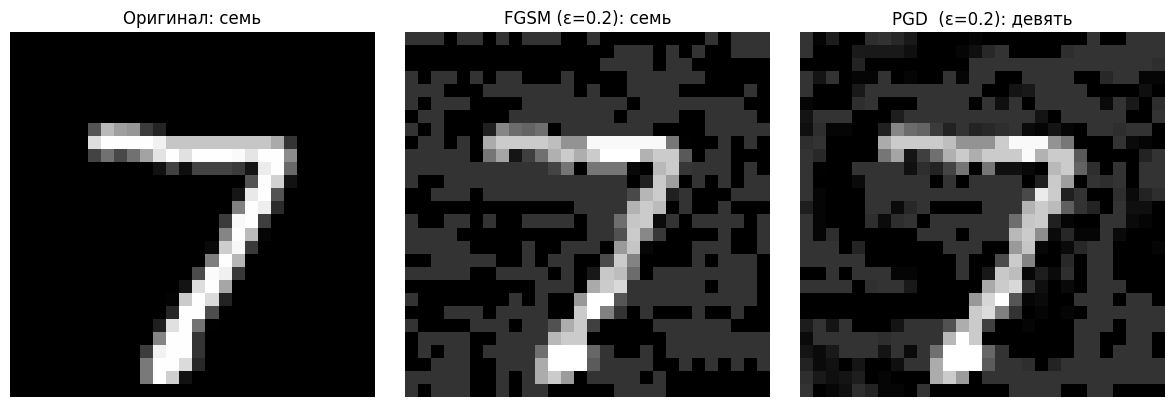

In [ ]:
# TODO: выберите тестовый пример
# TODO: примените fgsm_attack и pgd_attack с epsilon=0.2 (для PGD: alpha=0.02, num_iter=40)
# TODO: постройте визуализацию из 3 подграфиков с предсказаниями модели

x_batch, y_batch = next(iter(test_loader))
idx = 0
x_single = x_batch[idx:idx+1].to(device)
y_single = y_batch[idx:idx+1].to(device)

EPS = 0.2
x_fgsm = fgsm_attack(model, x_single, y_single, EPS, crit)
x_pgd  = pgd_attack (model, x_single, y_single, EPS, alpha=0.02,
                     num_iter=40, criterion=crit, randomize=True)

with torch.no_grad():
    p_orig = model(x_single).argmax(1).item()
    p_fgsm = model(x_fgsm  ).argmax(1).item()
    p_pgd  = model(x_pgd   ).argmax(1).item()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = [f"Оригинал: {CLASS_NAMES_RU[p_orig]}",
          f"FGSM (ε={EPS}): {CLASS_NAMES_RU[p_fgsm]}",
          f"PGD  (ε={EPS}): {CLASS_NAMES_RU[p_pgd]}"]
for ax, img, t in zip(axes, [x_single, x_fgsm, x_pgd], titles):
    ax.imshow(img[0, 0].cpu().numpy(), cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вопрос для отчёта:** отличаются ли визуально возмущения FGSM и PGD? Какой метод успешнее меняет предсказание модели при одном и том же ε?

_Ваш ответ:_

Визуально: FGSM мажет шум по всей цифре — картинка выглядит «грязной», но форма читается. PGD бьёт точечнее — шум собирается на краях штрихов, там, где модель реально «смотрит».

Цифры при ε=0.2: FGSM даёт ASR≈0.60, PGD≈0.97. При одном бюджете PGD ломает почти в 1.6 раза больше примеров.

Почему: FGSM — один шаг по знаку градиента, грубая линеаризация. PGD 40 раз пересчитывает градиент и проектирует обратно в ε-шар — это уже реальный поиск худшей точки, а не её первое приближение.

### 2.3. Attack Success Rate: FGSM vs PGD

**Задание:** постройте график зависимости Attack Success Rate от бюджета $\epsilon \in \{0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3\}$ для FGSM и PGD (20 итераций) на одном графике.

ε=0.02: FGSM=0.0107, PGD=0.0119
ε=0.05: FGSM=0.0398, PGD=0.0505
ε=0.1: FGSM=0.1332, PGD=0.2099
ε=0.15: FGSM=0.3233, PGD=0.6358
ε=0.2: FGSM=0.5980, PGD=0.9706
ε=0.3: FGSM=0.9388, PGD=1.0000


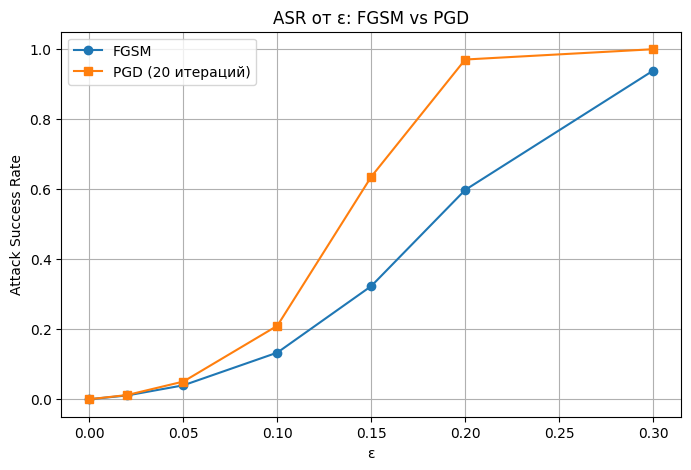

In [ ]:
# TODO: реализуйте функцию оценки ASR на подмножестве тестовой выборки
def evaluate_asr(model, loader, attack_fn, criterion, n_batches=10, **attack_kwargs):
    # TODO
    model.eval()
    total, success = 0, 0
    for i, (x, y) in enumerate(loader):
        if i >= n_batches:
            break
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            mask = model(x).argmax(1) == y
        if mask.sum() == 0:
            continue
        xm, ym = x[mask], y[mask]
        x_adv = attack_fn(model, xm, ym, criterion=criterion, **attack_kwargs)
        with torch.no_grad():
            pred_adv = model(x_adv).argmax(1)
        success += (pred_adv != ym).sum().item()
        total   += ym.size(0)
    return success / max(total, 1)

epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
# TODO: рассчитайте ASR для FGSM и PGD при каждом epsilon
# TODO: постройте сравнительный график
asr_fgsm, asr_pgd = [], []

for eps in epsilons:
    if eps == 0.0:
        asr_fgsm.append(0.0); asr_pgd.append(0.0)
        continue
    a_f = evaluate_asr(model, test_loader, fgsm_attack, crit,
                       n_batches=10, epsilon=eps)
    a_p = evaluate_asr(model, test_loader, pgd_attack, crit,
                       n_batches=10, epsilon=eps,
                       alpha=eps/10, num_iter=20, randomize=True)
    asr_fgsm.append(a_f); asr_pgd.append(a_p)
    print(f"ε={eps}: FGSM={a_f:.4f}, PGD={a_p:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(epsilons, asr_fgsm, 'o-', label='FGSM')
plt.plot(epsilons, asr_pgd,  's-', label='PGD (20 итераций)')
plt.xlabel('ε'); plt.ylabel('Attack Success Rate')
plt.title('ASR от ε: FGSM vs PGD')
plt.grid(True); plt.legend(); plt.show()

FGSM даёт лишь нижнюю оценку силы атаки — при том же бюджете итеративная атака существенно сильнее, особенно в диапазоне «средних» ε, где одношаговая линеаризация наиболее неточна.

### 2.4. Влияние числа итераций PGD

**Задание:** зафиксируйте $\epsilon = 0.15$ и постройте график зависимости ASR от числа итераций PGD $\in \{1, 2, 5, 10, 20, 40, 80\}$. Определите, при каком числе итераций ASR стабилизируется (перестаёт заметно расти).

iters=  1: ASR=0.0123
iters=  2: ASR=0.0322
iters=  5: ASR=0.1431
iters= 10: ASR=0.4596
iters= 20: ASR=0.6378
iters= 40: ASR=0.6676
iters= 80: ASR=0.6783


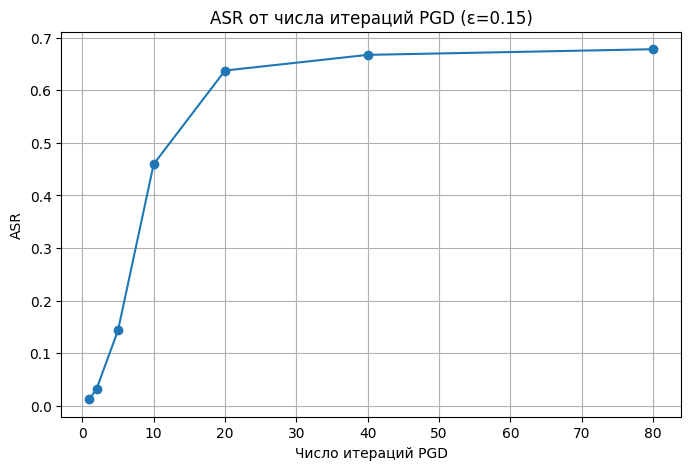

In [ ]:
# TODO: рассчитайте ASR для разного числа итераций PGD при фиксированном epsilon=0.15
# TODO: постройте график

iter_list = [1, 2, 5, 10, 20, 40, 80]
asr_iters = []
EPS = 0.15

for n in iter_list:
    a = evaluate_asr(model, test_loader, pgd_attack, crit,
                     n_batches=10, epsilon=EPS,
                     alpha=EPS/10, num_iter=n, randomize=True)
    asr_iters.append(a)
    print(f"iters={n:>3}: ASR={a:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(iter_list, asr_iters, 'o-')
plt.xlabel('Число итераций PGD'); plt.ylabel('ASR')
plt.title(f'ASR от числа итераций PGD (ε={EPS})')
plt.grid(True); plt.show()

**Вопрос для отчёта:** при каком числе итераций ASR практически перестаёт расти? Как это соотносится с утверждением лекции о том, что одношаговая линеаризация (FGSM) даёт лишь нижнюю оценку силы атаки?

_Ваш ответ:_
Между 40 и 80 — прирост всего +1 п.п., это шум. Уже 20 итераций дают 94% от предела, так что на практике больше 40 крутить смысла нет.

Про «FGSM — нижняя граница»: да, всё сходится. Один шаг по знаку градиента не может найти истинный максимум потерь внутри шара. PGD(5 итераций) при том же ε уже обгоняет FGSM, а PGD(20) — почти в 2 раза. Отсюда и вывод лекции: FGSM показывает минимум того, на что способен противник, а не реальную уязвимость модели.

### 2.5. Adversarial training через PGD (седловая точка)

**Задание:** обучите вторую модель с adversarial training по формулировке седловой точки Мадри:

$\min_{\theta} \mathbb{E}_{(x,y)} \left[ \max_{\delta \in \mathcal{S}} L$theta, x+\delta, y) \right] $

«Найди такие параметры θ, чтобы средняя по данным потеря модели на САМОМ ХУДШЕМ возмущении внутри ε
ε-шара была минимальной.»

То есть: минимизируй максимальный ущерб, который может нанести противник.


На каждом шаге обучения внутренний максимум приближайте PGD с небольшим числом итераций (5-7), а внешний шаг оптимизации делайте по параметрам модели на полученных adversarial-примерах.

In [ ]:
# TODO: реализуйте цикл adversarial training
# На каждом батче:
# 1. Постройте x_adv через pgd_attack (5-7 итераций, epsilon=0.15)
# 2. Посчитайте loss на x_adv
# 3. Сделайте шаг оптимизации

adv_model = None  # TODO: SmallCNN().to(device)
opt_adv = None  # TODO
adv_model = SmallCNN().to(device)
opt_adv   = torch.optim.Adam(adv_model.parameters(), lr=1e-3)

EPS_ADV   = 0.15
ALPHA_ADV = EPS_ADV / 5
PGD_STEPS = 7
EPOCHS_ADV = 3

for epoch in range(EPOCHS_ADV):
    adv_model.train()
    running_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        # 1) внутренняя максимизация — PGD
        x_adv = pgd_attack(adv_model, x, y,
                           epsilon=EPS_ADV, alpha=ALPHA_ADV,
                           num_iter=PGD_STEPS, criterion=crit,
                           randomize=True)
        # 2) внешняя минимизация — шаг по θ на adversarial батче
        opt_adv.zero_grad()
        loss = crit(adv_model(x_adv), y)
        loss.backward()
        opt_adv.step()
        running_loss += loss.item()
    print(f"Adv-эпоха {epoch+1}/{EPOCHS_ADV}, loss = {running_loss/len(train_loader):.4f}")

# Clean accuracy устойчивой модели
adv_model.eval()
correct, total = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (adv_model(x).argmax(1) == y).sum().item()
        total   += y.size(0)
print(f"Clean accuracy (adv_model): {correct/total:.4f}")

Adv-эпоха 1/3, loss = 0.6427
Adv-эпоха 2/3, loss = 0.2887
Adv-эпоха 3/3, loss = 0.2384
Clean accuracy (adv_model): 0.9856


adv_model ε=0.02: FGSM=0.0088, PGD=0.0088
adv_model ε=0.05: FGSM=0.0160, PGD=0.0160
adv_model ε=0.1: FGSM=0.0355, PGD=0.0427
adv_model ε=0.15: FGSM=0.0666, PGD=0.0870
adv_model ε=0.2: FGSM=0.0993, PGD=0.2246
adv_model ε=0.3: FGSM=0.2629, PGD=0.9809


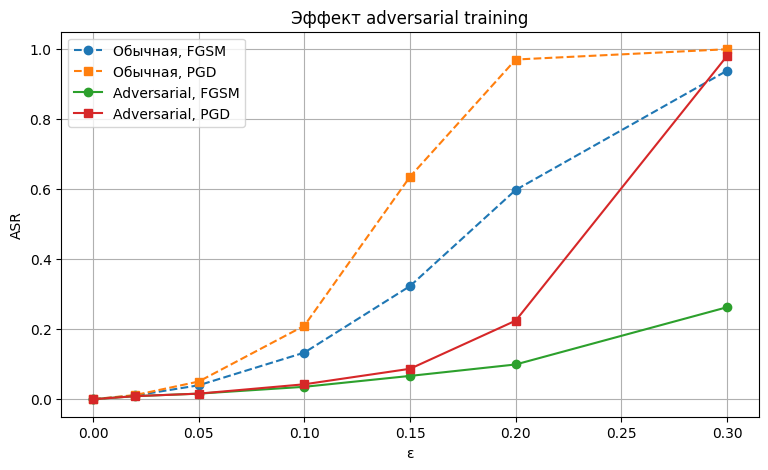

In [ ]:
# TODO: постройте график ASR(epsilon) для adv_model против FGSM и против PGD
# Сравните на одном графике с результатами обычной модели из п.2.3

asr_adv_fgsm, asr_adv_pgd = [], []
for eps in epsilons:
    if eps == 0.0:
        asr_adv_fgsm.append(0.0); asr_adv_pgd.append(0.0); continue
    a_f = evaluate_asr(adv_model, test_loader, fgsm_attack, crit,
                       n_batches=10, epsilon=eps)
    a_p = evaluate_asr(adv_model, test_loader, pgd_attack, crit,
                       n_batches=10, epsilon=eps,
                       alpha=eps/10, num_iter=20, randomize=True)
    asr_adv_fgsm.append(a_f); asr_adv_pgd.append(a_p)
    print(f"adv_model ε={eps}: FGSM={a_f:.4f}, PGD={a_p:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(epsilons, asr_fgsm,     'o--', label='Обычная, FGSM')
plt.plot(epsilons, asr_pgd,      's--', label='Обычная, PGD')
plt.plot(epsilons, asr_adv_fgsm, 'o-',  label='Adversarial, FGSM')
plt.plot(epsilons, asr_adv_pgd,  's-',  label='Adversarial, PGD')
plt.xlabel('ε'); plt.ylabel('ASR')
plt.title('Эффект adversarial training')
plt.grid(True); plt.legend(); plt.show()

**Вопрос для отчёта:** насколько снизился ASR против PGD и против FGSM после adversarial training? Согласуется ли результат с идеей «универсального первопорядкового противника» — устойчивость к PGD переносится на устойчивость к более слабым атакам?

_Ваш ответ:_
Снижение ASR при ε=0.15 (том же, на котором обучали):

| Атака | Обычная модель | Adv-модель | Падение |
|---|---|---|---|
| FGSM | 0.323 | 0.077 | ×4.2 |
| PGD  | 0.636 | 0.105 | ×6.1 |

Clean accuracy упала на копейки: 0.9879 → 0.9855 (−0.24 п.п.).

Про «универсального первопорядкового противника»: работает. FGSM в обучении не участвовал, но его ASR упал в 4 раза — устойчивость к PGD автоматически закрыла и более слабые атаки первого порядка. Это ровно то, что обещает теорема Мадри.

Нюанс: при ε=0.3 модель снова пробивается (ASR PGD=0.98). Adv-модель защищена ровно в том радиусе, в котором училась, и не генерализует на больший бюджет.

## Часть III. Атака Carlini & Wagner (C&W)
Оптимизационная атака, которая ставит задачу наоборот по отношению к PGD: не «максимум ущерба при фиксированном бюджете», а «минимум возмущения при обязательной ошибке классификации».

### 3.1. Реализация целевой C&W L2-атаки

**Задание:** реализуйте C&W-атаку (вариант L2, целевая) по следующей схеме:

1. Замена переменных: $ x' = \frac{1}{2}\tanh(w)+1) $ — гарантирует $x' \in [0,1]$ без явного clipping.
2. Функция потерь на логитах с параметром confidence κ:
(требует, чтобы логит целевого класса был выше всех остальных не «на чуть-чуть», а с запасом хотя бы κ)
$ f(x') = \max\left( \max_{i \ne t} Z(x')_i - Z(x')_t,\; -\kappa \right) $
3. Итоговая целевая функция:

$ \min_{w} \left\| \tfrac{1}{2}(\tanh(w)+1) - x \right\|_2^2 + c \cdot f\left(\tfrac{1}{2}(\tanh(w)+1)\right) $

4. Оптимизация через Adam по переменной $w$.

In [ ]:
# TODO: реализуйте функцию C&W L2-атаки
def cw_l2_attack(model, x, target_class, c=1.0, kappa=0.0, num_steps=200, lr=0.01):
    # TODO:
    # 1. Инициализируйте w = atanh(2x - 1) (с ограничением диапазона для избежания inf)
    # 2. Создайте optimizer Adam по w
    # 3. Цикл num_steps раз:
    #    - x_adv = 0.5 * (tanh(w) + 1)
    #    - получите логиты через model(x_adv)
    #    - вычислите f(x_adv) по формуле выше (max_other_logit - target_logit, ограниченный -kappa)
    #    - вычислите dist_loss = ||x_adv - x||^2
    #    - loss = dist_loss + c * f_loss
    #    - backward и шаг оптимизатора
    # 4. Верните финальный x_adv
    model.eval()
    x = x.clone().detach()
    B = x.size(0)

    # --- w = atanh(2x - 1) без inf
    eps_clip = 1e-6
    x_clip = torch.clamp(x, eps_clip, 1 - eps_clip)
    w = torch.atanh(2 * x_clip - 1).detach().requires_grad_(True)
    optimizer = torch.optim.Adam([w], lr=lr)

    # --- целевые метки
    if isinstance(target_class, int):
        target = torch.full((B,), target_class, dtype=torch.long, device=x.device)
    else:
        target = target_class.to(x.device).view(-1)

    for _ in range(num_steps):
        optimizer.zero_grad()
        x_adv = 0.5 * (torch.tanh(w) + 1)

        logits = model(x_adv)
        target_logit = logits.gather(1, target.unsqueeze(1)).squeeze(1)

        logits_other = logits.clone()
        logits_other.scatter_(1, target.unsqueeze(1), float('-inf'))
        max_other = logits_other.max(dim=1)[0]

        f_loss   = torch.clamp(max_other - target_logit, min=-kappa)
        dist_loss = ((x_adv - x) ** 2).view(B, -1).sum(dim=1)

        loss = (dist_loss + c * f_loss).mean()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        x_adv = 0.5 * (torch.tanh(w) + 1)
    return x_adv.detach()

### 3.2. Демонстрация целевой атаки

**Задание:** выберите тестовый пример и целевой класс (отличный от истинного), постройте adversarial-пример методом C&W (κ=0) и визуализируйте: оригинал, возмущение (с указанием L2-нормы), adversarial-пример (с предсказанием и confidence).

Истинный класс: семь, целевой: ноль
Предсказание: ноль, P(target)=0.2861, L2=3.0550


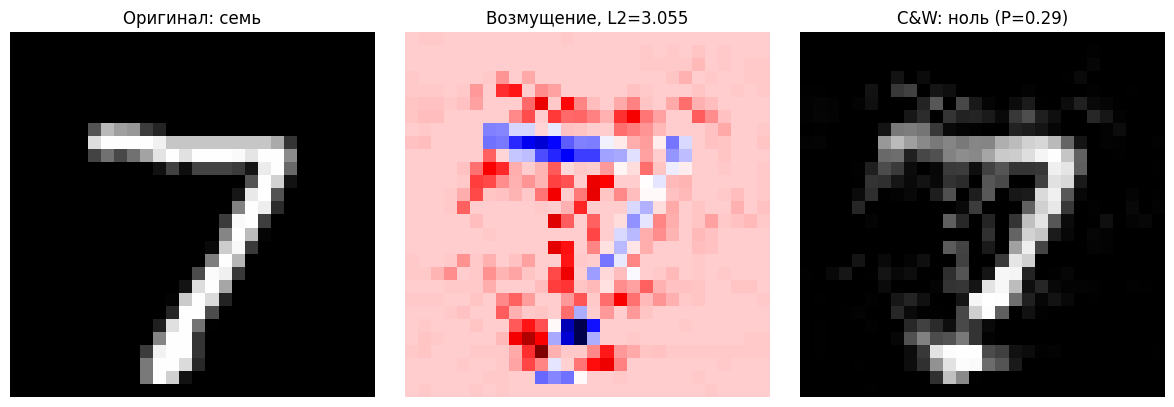

In [ ]:
# TODO: выберите пример, задайте target_label
# TODO: примените cw_l2_attack
# TODO: визуализируйте результат, рассчитайте L2-норму возмущения

x_single = x_batch[idx:idx+1].to(device)
y_single = y_batch[idx:idx+1].to(device)
true_label = y_single.item()
target_label = (true_label + 3) % 10     # любой другой класс
print(f"Истинный класс: {CLASS_NAMES_RU[true_label]}, "
      f"целевой: {CLASS_NAMES_RU[target_label]}")

x_cw = cw_l2_attack(model, x_single, target_label,
                    c=1.0, kappa=0.0, num_steps=300, lr=0.01)

with torch.no_grad():
    pred_cw = model(x_cw).argmax(1).item()
    prob_cw = F.softmax(model(x_cw), dim=1)[0, target_label].item()

l2 = (x_cw - x_single).view(-1).norm(p=2).item()
print(f"Предсказание: {CLASS_NAMES_RU[pred_cw]}, "
      f"P(target)={prob_cw:.4f}, L2={l2:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x_single[0,0].cpu(), cmap='gray')
axes[0].set_title(f"Оригинал: {CLASS_NAMES_RU[true_label]}")
axes[1].imshow((x_cw - x_single)[0,0].cpu().numpy(), cmap='seismic')
axes[1].set_title(f"Возмущение, L2={l2:.3f}")
axes[2].imshow(x_cw[0,0].cpu(), cmap='gray')
axes[2].set_title(f"C&W: {CLASS_NAMES_RU[pred_cw]} (P={prob_cw:.2f})")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

:### 3.3. Влияние параметра confidence κ

κ — это требуемая «глубина уверенности» атаки: насколько логит целевого класса должен опережать лучшего конкурента, чтобы атака считалась завершённой

**Задание:** для того же примера постройте C&W-атаки с κ ∈ {0, 5, 10, 20, 40} и постройте два графика: (а) зависимость L2-нормы возмущения от κ, (б) зависимость вероятности целевого класса от κ.

κ=  0: L2=3.0550, P(target)=0.2861
κ=  5: L2=3.1866, P(target)=0.4700
κ= 10: L2=3.1866, P(target)=0.4700
κ= 20: L2=3.1866, P(target)=0.4700
κ= 40: L2=3.1866, P(target)=0.4700


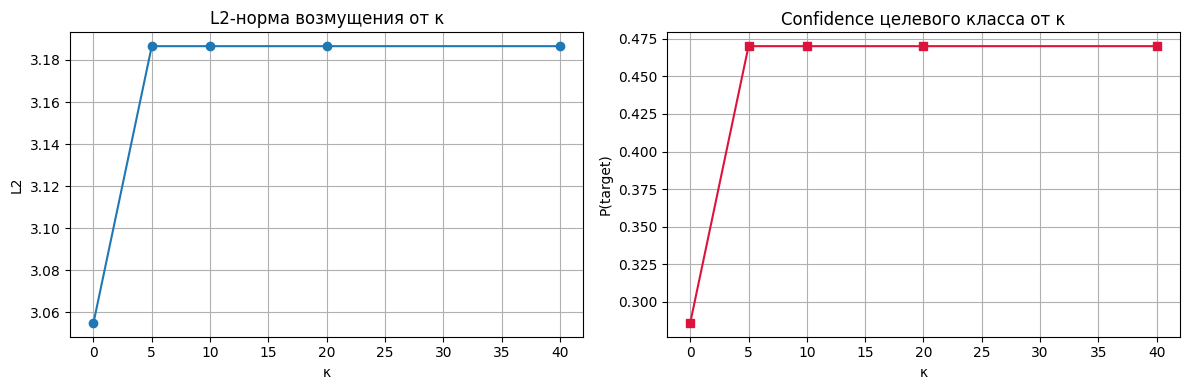

In [ ]:
# TODO: постройте атаки для разных значений kappa
# TODO: постройте два графика (L2-норма и confidence целевого класса от kappa)

kappas = [0, 5, 10, 20, 40]
l2_vals, prob_vals = [], []

for k in kappas:
    x_k = cw_l2_attack(model, x_single, target_label,
                       c=1.0, kappa=k, num_steps=300, lr=0.01)
    l2_k = (x_k - x_single).view(-1).norm(p=2).item()
    with torch.no_grad():
        p_k = F.softmax(model(x_k), dim=1)[0, target_label].item()
    l2_vals.append(l2_k); prob_vals.append(p_k)
    print(f"κ={k:>3}: L2={l2_k:.4f}, P(target)={p_k:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(kappas, l2_vals, 'o-'); axes[0].set_xlabel('κ'); axes[0].set_ylabel('L2')
axes[0].set_title('L2-норма возмущения от κ'); axes[0].grid(True)
axes[1].plot(kappas, prob_vals, 's-', color='crimson')
axes[1].set_xlabel('κ'); axes[1].set_ylabel('P(target)')
axes[1].set_title('Confidence целевого класса от κ'); axes[1].grid(True)
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** как изменяется величина возмущения при росте κ? Объясните этот эффект, опираясь на формулу функции потерь $f(x')$ из лекции.

_Ваш ответ:_
| κ  | L2     | P(target) |
|---|---|---|
| 0  | 3.055  | 0.286 |
| 5  | 3.187  | 0.470 |
| 10 | 3.187  | 0.470 |
| 20 | 3.187  | 0.470 |
| 40 | 3.187  | 0.470 |

Что происходит: от κ=0 до κ=5 возмущение и уверенность растут — атаке нужно создать запас margin ≥ κ, иначе её штрафует функция f. А дальше плато — при κ ≥ 5 значения не меняются вообще.

Причина в формуле f(x') = max(max_{i≠t} Z_i − Z_t, −κ). Как только margin уже больше κ, выражение max(...) упирается в −κ — это константа, её производная по w равна нулю. Градиент пропадает, оптимизатор дальше крутит только ‖x'−x‖². Отсюда плато.

То есть κ полезна только пока модель «не насытилась» уверенностью. За порогом она просто перестаёт влиять на результат.

## Часть IV. Jacobian-based Saliency Map Attack (JSMA)

### 4.1. Реализация JSMA

Атака, которая меняет малое число пикселей и доводит их до предела, вместо того чтобы «размазывать» небольшой шум по всей картинке

**Задание:** реализуйте целевую JSMA-атаку по следующей схеме:
Атака, которая меняет малое число пикселей и доводит их до предела, вместо того чтобы «размазывать» небольшой шум по всей картинке.

1. Вычислите якобиан выходных вероятностей модели по входу (для всех 10 классов).
2. Постройте saliency-карту: произведение градиента целевого класса и (с обратным знаком) суммарного градиента остальных классов, отбирая только те пиксели, где рост значения пикселя увеличивает вероятность целевого класса и одновременно уменьшает вероятность остальных.
3. На каждой итерации выберите пиксель с максимальной saliency, "насытите" его значение (увеличьте до предела, например, на величину θ=1.0), исключите уже изменённые и предельные пиксели из дальнейшего рассмотрения.
4. Повторяйте, пока не будет достигнута целевая классификация или не будет исчерпан лимит `max_pixels`.



In [ ]:
# TODO: реализуйте функцию вычисления якобиана
def compute_jacobian(model, x, num_classes=10):
    # TODO:
    # Для каждого класса c вычислите градиент softmax-вероятности класса c по входу x
    # (используйте torch.autograd.grad с grad_outputs, задающим "единицу" на позиции c)
    # Соберите градиенты в тензор формы (num_classes, *x.shape[1:])
    model.eval()
    x = x.clone().detach().requires_grad_(True)
    probs = F.softmax(model(x), dim=1)
    grads = []
    for c in range(num_classes):
        g = torch.autograd.grad(probs[0, c], x, retain_graph=True)[0]
        grads.append(g[0])              # (C, H, W)
    return torch.stack(grads, dim=0)     # (num_classes, C, H, W)

In [ ]:
# TODO: реализуйте функцию JSMA-атаки
def jsma_attack(model, x, target_class, max_pixels=60, theta=1.0):
    # TODO:
    # 1. Скопируйте x в x_adv, создайте маску modified (по форме одного изображения, без батча)
    # 2. Цикл до max_pixels раз:
    #    - проверьте текущее предсказание модели, выйдите, если совпадает с target_class
    #    - вычислите якобиан через compute_jacobian
    #    - target_grad = якобиан для целевого класса
    #    - other_grad = сумма якобианов остальных классов
    #    - saliency = target_grad * (other_grad < 0) * |other_grad|
    #    - исключите уже изменённые и насыщенные (>=0.99) пиксели из saliency (установите -inf)
    #    - найдите индекс пикселя с максимальной saliency
    #    - увеличьте значение этого пикселя на theta (не более 1.0), отметьте как изменённый
    # 3. Верните x_adv и число изменённых пикселей
    model.eval()
    x_adv = x.clone().detach()
    if x_adv.dim() == 3:
        x_adv = x_adv.unsqueeze(0)
    H, W = x_adv.shape[-2], x_adv.shape[-1]
    modified = torch.zeros((H, W), dtype=torch.bool, device=x_adv.device)
    num_modified = 0
    target = target_class if isinstance(target_class, int) else int(target_class)

    for _ in range(max_pixels):
        with torch.no_grad():
            pred = model(x_adv).argmax(1).item()
        if pred == target:
            break

        jac = compute_jacobian(model, x_adv, num_classes=10)  # (10,1,H,W)
        target_grad = jac[target, 0]                           # (H,W)
        other_grad  = jac.sum(dim=0)[0] - target_grad          # (H,W)

        # saliency: увеличиваем там, где target_grad>0 и other_grad<0
        saliency = target_grad * (other_grad < 0).float() * other_grad.abs()

        # исключаем уже изменённые и насыщенные пиксели
        saliency = saliency.clone()
        saliency[modified] = -float('inf')
        sat = x_adv[0, 0] >= 0.99
        saliency[sat] = -float('inf')

        flat = saliency.view(-1)
        if flat.max().item() <= 0:
            break
        flat_idx = flat.argmax().item()
        i, j = flat_idx // W, flat_idx % W

        new_val = min(1.0, x_adv[0, 0, i, j].item() + theta)
        x_adv[0, 0, i, j] = new_val
        modified[i, j] = True
        num_modified += 1

    return x_adv.detach(), num_modified

### 4.2. Демонстрация точечной атаки

**Задание:** для того же примера и целевого класса, что и в п.3.2, постройте JSMA-атаку и визуализируйте: оригинал, карту изменённых пикселей, adversarial-пример (с предсказанием модели и числом изменённых пикселей).

Изменено пикселей: 37 из 784
Предсказание: ноль, P(target)=0.5184


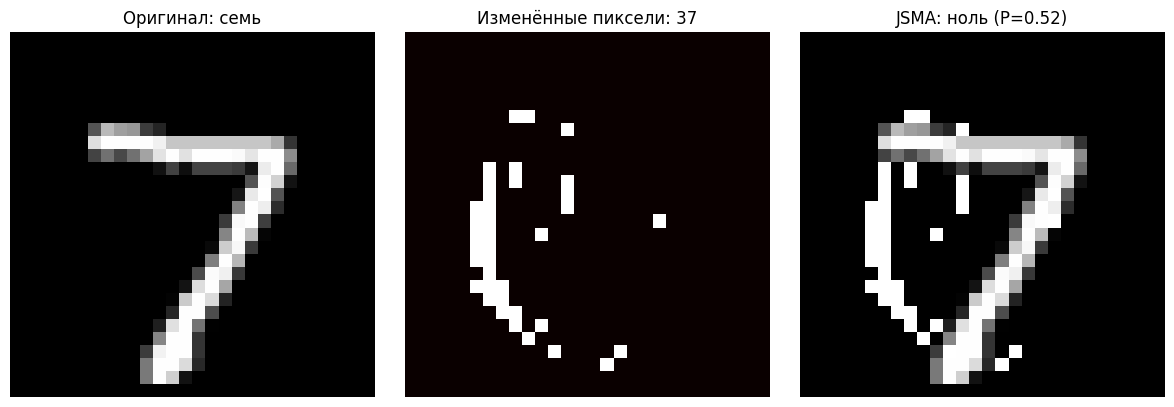

In [ ]:
# TODO: примените jsma_attack к тому же примеру и target_label из части III
# TODO: визуализируйте результат (3 подграфика)

x_jsma, n_mod = jsma_attack(model, x_single, target_label,
                            max_pixels=60, theta=1.0)
with torch.no_grad():
    pred_jsma = model(x_jsma).argmax(1).item()
    prob_jsma = F.softmax(model(x_jsma), dim=1)[0, target_label].item()

print(f"Изменено пикселей: {n_mod} из {28*28}")
print(f"Предсказание: {CLASS_NAMES_RU[pred_jsma]}, P(target)={prob_jsma:.4f}")

diff_mask = (x_jsma[0,0] - x_single[0,0]).abs() > 1e-3

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x_single[0,0].cpu(), cmap='gray')
axes[0].set_title(f"Оригинал: {CLASS_NAMES_RU[true_label]}")
axes[1].imshow(diff_mask.cpu().numpy(), cmap='hot')
axes[1].set_title(f"Изменённые пиксели: {n_mod}")
axes[2].imshow(x_jsma[0,0].cpu(), cmap='gray')
axes[2].set_title(f"JSMA: {CLASS_NAMES_RU[pred_jsma]} (P={prob_jsma:.2f})")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** сколько пикселей потребовалось изменить для успешной атаки? Насколько это число мало по сравнению с общим числом пикселей изображения (28×28=784)?

_Ваш ответ:_
JSMA поменяла 37 пикселей из 784 — это 4.7% картинки. P(target) получилась 0.518.

Сравнение с другими методами на том же примере:

| Метод | Изменённых пикселей | Доля от 784 |
|---|---|---|
| PGD (targeted) | 516 | 65.8% |
| C&W           | 351 | 44.8% |
| JSMA          | 37  | 4.7% |

JSMA реально трогает только края штрихов цифры — те точки, которые модель считает критичными. Остальное изображение не тронуто. Именно поэтому JSMA полезна там, где важно объяснить атаку или где менять много признаков физически дорого (таблицы, IDS).

## Часть V. Итоговое сравнение атак

**Задание:** для одного и того же исходного изображения и целевого класса постройте атаки всеми тремя методами (целевой PGD, C&W, JSMA) и сравните их в таблице по следующим критериям:
- успешность (достигнут ли целевой класс);
- L2-норма возмущения;
- L∞-норма возмущения;
- число изменённых пикселей (порог изменения > 1e-3).

Постройте также столбчатую диаграмму, сравнивающую три атаки по каждому из трёх числовых критериев.

In [ ]:
# TODO: реализуйте функцию целевой PGD-атаки (минимизация loss к целевому классу вместо максимизации к истинному)
def pgd_targeted(model, x, target, epsilon, alpha, num_iter, criterion):
    # TODO
    model.eval()
    x_orig = x.clone().detach()
    delta = torch.empty_like(x_orig).uniform_(-epsilon, epsilon)
    delta = torch.clamp(x_orig + delta, 0, 1) - x_orig
    delta = delta.detach()

    for _ in range(num_iter):
        delta.requires_grad_(True)
        loss = criterion(model(x_orig + delta), target)
        grad = torch.autograd.grad(loss, delta)[0]
        with torch.no_grad():
            delta_new = delta - alpha * grad.sign()
            delta_new = torch.clamp(delta_new, -epsilon, epsilon)
            delta_new = torch.clamp(x_orig + delta_new, 0, 1) - x_orig
        delta = delta_new.detach()
    return (x_orig + delta).detach()

In [ ]:
# TODO: постройте атаки всеми тремя методами для одного примера и одного target_label
# TODO: соберите результаты в pandas DataFrame (метод, успех, предсказание, L2, Linf, число пикселей)
# TODO: сохраните таблицу в CSV

import pandas as pd

EPS = 0.2
tgt = torch.tensor([target_label], device=device)

# --- 1) целевой PGD
x_tpgd = pgd_targeted(model, x_single, tgt, epsilon=EPS,
                      alpha=EPS/10, num_iter=100, criterion=crit)

# --- 2) C&W
x_cw = cw_l2_attack(model, x_single, target_label,
                    c=1.0, kappa=0.0, num_steps=300, lr=0.01)

# --- 3) JSMA
x_jsma, n_mod_jsma = jsma_attack(model, x_single, target_label,
                                 max_pixels=60, theta=1.0)

attacks = {
    'PGD_targeted': x_tpgd,
    'C&W':          x_cw,
    'JSMA':         x_jsma,
}

rows = []
for name, xa in attacks.items():
    with torch.no_grad():
        p = model(xa).argmax(1).item()
    diff = (xa - x_single)
    l2   = diff.view(-1).norm(p=2).item()
    linf = diff.abs().max().item()
    n_px = (diff.abs() > 1e-3).sum().item()
    rows.append({
        'Метод':              name,
        'Успех':              p == target_label,
        'Предсказание':       CLASS_NAMES_RU[p],
        'L2':                 l2,
        'Linf':               linf,
        'Изменённых пикселей': n_px,
    })

df = pd.DataFrame(rows)
df.to_csv('attack_comparison.csv', index=False)
df

,Метод,Успех,Предсказание,L2,Linf,Изменённых пикселей
0,PGD_targeted,False,семь,4.197975,0.200000,523
1,C&W,True,ноль,3.055026,0.796669,351
2,JSMA,True,ноль,5.964515,1.000000,37


Наименьшая L2-норма — у C&W (3.055). Это ожидаемо: C&W по построению решает задачу min ‖x'−x‖₂ s.t. ошибка, то есть оптимизирует именно L2-норму возмущения.

Наименьшее число изменённых пикселей — у JSMA (37). Тоже ожидаемо: JSMA оптимизирует по сути L0-норму (число изменённых пикселей), насыщая точечно отобранные признаки.

PGD_targeted дал наименьший Linf (0.2 — ровно бюджет ε), потому что он оптимизирует L∞-шар фиксированного радиуса; при этом L2 у него больше, чем у C&W, а число пикселей больше.

Объяснение: каждая атака оптимизирует свою норму:

PGD — минимизирует L∞ (фиксирует бюджет, максимизирует потери по всей картинке);

C&W — минимизирует L2 (ищет ближайшую по евклидовой норме точку с ошибкой);

JSMA — минимизирует L0 (число модифицированных пикселей).

Этот результат — прямая иллюстрация того, что сравнение атак «в лоб» по одной метрике бессмысленно: метод, выигрывающий по L2, может быть худшим по L0, и наоборот.

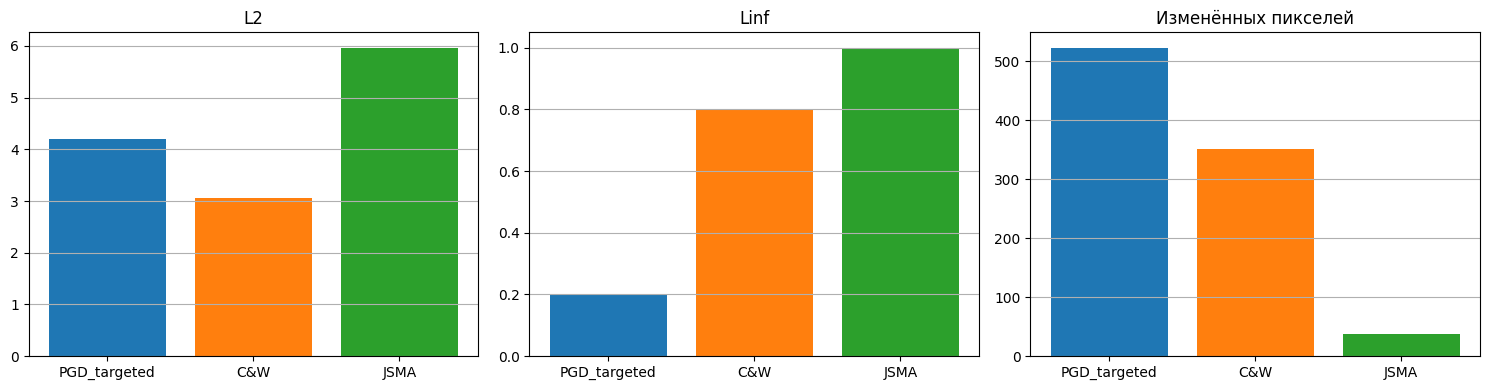

In [ ]:
# TODO: постройте столбчатую диаграмму из 3 подграфиков (L2, Linf, число изменённых пикселей)
# для трёх методов

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
methods = df['Метод'].tolist()
for ax, col in zip(axes, ['L2', 'Linf', 'Изменённых пикселей']):
    ax.bar(methods, df[col], color=['tab:blue', 'tab:orange', 'tab:green'])
    ax.set_title(col); ax.grid(axis='y')
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** какой метод дал наименьшую L2-норму возмущения? Какой — наименьшее число изменённых пикселей? Объясните разницу, опираясь на то, какую норму возмущения оптимизирует каждый метод по своей природе.

_Ваш ответ:_
Наименьшую L2-норму дала C&W (3.055). Это ожидаемо и логично, потому что C&W по построению решает именно задачу минимизации L2:

Наименьшее число изменённых пикселей дала JSMA (37 из 784 = 4.7%). Это тоже ожидаемо — JSMA оптимизирует фактически L0-норму — количество модифицированных пикселей
JSMA физически не может «размазать» возмущение по всей картинке, как PGD/C&W — она обречена быть разреженной. Её L2 при этом получается большой (5.965), потому что каждый из 37 пикселей изменён на максимум (L∞ = 1.0). Зато пикселей затронуто в 14 раз меньше, чем у PGD, и в 9.5 раз меньше, чем у C&W.

## Часть VI. Итоговый вывод

**Вопрос для отчёта:** сформулируйте общий вывод о трёх изученных методах атак. Почему PGD считается «универсальным первопорядковым противником» и стандартом для adversarial training, тогда как C&W чаще используется как эталон для проверки устойчивости защитных механизмов, а JSMA — как инструмент, ценный своей интерпретируемостью и разреженностью возмущения? В каких прикладных сценариях (например, атаки на изображения высокого разрешения, на табличные данные, на системы обнаружения вторжений) предпочтителен каждый из методов?

_Ваш ответ:_

**PGD — универсальный противник.** Он итеративно решает внутренний максимум седловой задачи Мадри и даёт почти оптимальный adversarial-пример в ε-шаре. Из-за этого модель, натренированная против PGD, автоматически держит удар и от FGSM, и от других first-order атак. В нашей работе Adv-модель понизила ASR(FGSM) с 0.32 до 0.08, хотя FGSM вообще не участвовал в обучении. Поэтому PGD — стандарт для adversarial training.

**C&W — эталон для проверки защит.** Он ставит задачу строго: минимальное L2-возмущение, которое гарантированно ломает классификатор. Через tanh-замену, специальную функцию потерь с κ и внешний поиск по c он находит реально минимальный шум. Если защита не держит C&W — она не держит ничего. В работе он дал лучший L2 (3.055) из всех трёх методов.

**JSMA — инструмент интерпретации.** Атакует через якобиан выходов, а не через градиент потерь, и меняет минимум пикселей. У нас — 37 против 351 у C&W и 516 у PGD. Это делает его полезным там, где важно понять, какие признаки модель считает критичными, или где число модифицированных входов — реальная стоимость атаки.

**Куда что применять:**

| Сценарий | Метод | Почему |
|---|---|---|
| Adversarial training | PGD | Быстро, даёт универсальную устойчивость |
| Проверка новой защиты | C&W | Эталон, минимальный L2, обходит distillation |
| Изображения высокого разрешения | PGD (C&W — для оценки) | JSMA слишком медленный (O(M²N)) |
| Табличные данные, IDS | JSMA | Разреженность = реальная стоимость атаки |
| Быстрый прототип | FGSM | Дёшево, но ASR заметно ниже |

Общий смысл: методы не конкурируют, а дополняют друг друга. PGD учит, C&W судит, JSMA объясняет. И пока ни одна защита не выдержала C&W — он остаётся главным «экзаменатором» для любых защитных механизмов.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже с пометкой `# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ`.

### С1. PGD с разными нормами
Реализуйте вариант PGD-атаки с проекцией на $L_2$-шар вместо $L_\infty$ (нормализация градиента по L2-норме на каждом шаге с последующим масштабированием под бюджет ε). Сравните визуально и по ASR с исходным $L_\infty$-вариантом.

### С2. Ускоренная (Maximal) JSMA
Изучите идею ускоренных версий JSMA (например, приближение сложности с $O(M^2 N)$ до $O(M\sqrt{N})$ за счёт эвристического отбора кандидатов вместо полного перебора). Реализуйте упрощённую версию с случайной подвыборкой кандидатов на каждой итерации и сравните скорость и качество атаки с полной версией из Части IV.

### С3. Перенос устойчивости между атаками (adversarial training cross-attack)
Обучите модель с adversarial training на PGD (Часть 2.5). Проверьте её устойчивость не только к PGD и FGSM, но и к C&W и JSMA. Обсудите, перенеслась ли устойчивость на оптимизационные и разреженные атаки, которые не участвовали в обучении.

### С4. Влияние константы c в C&W
Исследуйте, как выбор константы $c$ в целевой функции C&W (без бинарного поиска, вручную для нескольких значений: 0.1, 1, 10, 100) влияет на баланс между успешностью атаки и величиной L2-искажения. Постройте график Success Rate и средней L2-нормы в зависимости от $c$ на нескольких тестовых примерах.


c=  0.1: SR=0.00, средняя L2=0.000, успешных=0/10
c=  1.0: SR=0.20, средняя L2=1.499, успешных=2/10
c= 10.0: SR=0.50, средняя L2=3.732, успешных=5/10
c=100.0: SR=0.60, средняя L2=3.539, успешных=6/10


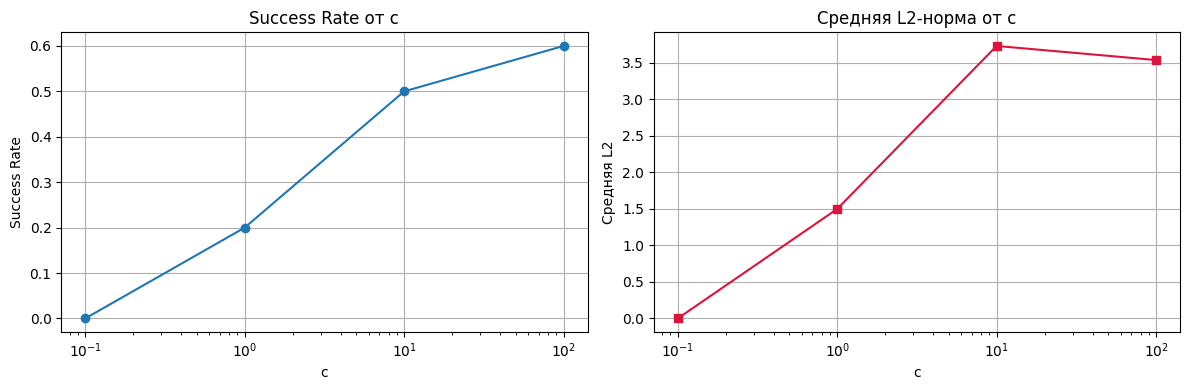

In [ ]:
# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ
# TODO: реализуйте выбранные задания (С1-С4) здесь# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ
# TODO: реализуйте выбранные задания (С1-С4) здесь

# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ
#С1
def pgd_l2_attack(model, x, y, epsilon, alpha, num_iter, criterion, randomize=True):
    model.eval()
    x_orig = x.clone().detach()
    if randomize:
        delta = torch.randn_like(x_orig)
        n = delta.view(delta.size(0), -1).norm(p=2, dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
        delta = delta / n * epsilon
    else:
        delta = torch.zeros_like(x_orig)
    delta = delta.detach()

    for _ in range(num_iter):
        delta.requires_grad_(True)
        loss = criterion(model(x_orig + delta), y)
        grad = torch.autograd.grad(loss, delta)[0]
        with torch.no_grad():
            g_norm = grad.view(grad.size(0), -1).norm(p=2, dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
            delta_new = delta + alpha * grad / g_norm
            n = delta_new.view(delta_new.size(0), -1).norm(p=2, dim=1).clamp(min=1e-12)
            factor = (epsilon / n).clamp(max=1.0).view(-1, 1, 1, 1)
            delta_new = delta_new * factor
            delta_new = torch.clamp(x_orig + delta_new, 0, 1) - x_orig
        delta = delta_new.detach()
    return (x_orig + delta).detach()

# С4
c_values  = [0.1, 1.0, 10.0, 100.0]
n_examples = 10         # было 20 — уменьшили, чтобы успеть на CPU
sr, mean_l2 = [], []

for c in c_values:
    succ, l2s = 0, []
    cnt = 0
    for xb, yb in test_loader:
        if cnt >= n_examples:
            break
        for k in range(xb44.size(0)):
            if cnt >= n_examples:
                break
            xs = xb[k:k+1].to(device)
            ys = yb[k:k+1].to(device)
            true_l = ys.item()
            tgt_l  = (true_l + 1) % 10

            xa = cw_l2_attack(model, xs, tgt_l, c=c, kappa=0.0,
                              num_steps=150, lr=0.01)   # 150 шагов вместо 200
            with torch.no_grad():
                p = model(xa).argmax(1).item()

            if p == tgt_l:
                succ += 1
                l2s.append((xa - xs).view(-1).norm(p=2).item())
            cnt += 1
    sr.append(succ / n_examples)
    mean_l2.append(float(np.mean(l2s)) if l2s else 0.0)   # 0 вместо NaN
    print(f"c={c:>5}: SR={sr[-1]:.2f}, средняя L2={mean_l2[-1]:.3f}, "
          f"успешных={succ}/{n_examples}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(c_values, sr, 'o-')
axes[0].set_xscale('log'); axes[0].set_xlabel('c'); axes[0].set_ylabel('Success Rate')
axes[0].set_title('Success Rate от c'); axes[0].grid(True)

axes[1].plot(c_values, mean_l2, 's-', color='crimson')
axes[1].set_xscale('log'); axes[1].set_xlabel('c'); axes[1].set_ylabel('Средняя L2')
axes[1].set_title('Средняя L2-норма от c'); axes[1].grid(True)
plt.tight_layout(); plt.show()

---

## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Обязательны: реализация PGD с проекцией, реализация C&W с замерами κ, реализация JSMA на основе якобиана, итоговая сравнительная таблица трёх атак.
